# Customer Review Text Mining – Women's Clothing

**Business question:** What do 23,000 customer reviews tell management about satisfaction, the topics customers raise, and where to act?

**Data:** `clothing_reviews.xlsx` (one row per review: title, review text, star rating, recommendation flag, age, product hierarchy).

**Approach** – following the toolkit from *1_Introduction* (Text Mining · Information Retrieval · NLP):

| Step | Method (lecture slide) |
|---|---|
| 1 | Load & clean the corpus |
| 2 | From text to numerical data: review length, word length, vocabulary, readability (slides 33–39) |
| 3 | NLP preprocessing: tokenization, stop-word removal, lemmatization (slide 23) |
| 4 | Word & n-gram frequencies, word clouds (slide 21) |
| 5 | Word co-occurrence (slide 21) |
| 6 | Document-term matrix & TF-IDF: what distinguishes negative from positive reviews (slide 22) |
| 7 | Sentiment analysis with VADER (slide 23) |
| 8 | Topic modeling with LDA (slides 21, 47–49) |
| 9 | Topics by department and age group |
| 10 | Key findings for management |

All charts are saved to `figures/`; key numbers to `results/key_numbers.json`.

In [1]:
import re, json, os, warnings
from collections import Counter
from itertools import combinations

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import nltk
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.decomposition import LatentDirichletAllocation
from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer
from wordcloud import WordCloud
import textstat

warnings.filterwarnings('ignore')
for pkg in ['stopwords', 'wordnet', 'omw-1.4']:
    nltk.download(pkg, quiet=True)

os.makedirs('figures', exist_ok=True)
os.makedirs('results', exist_ok=True)
pd.set_option('display.max_colwidth', 120)

# Chart style: one colour per job (blue = positive, orange = negative, grey = neutral)
POS, NEG, NEU = '#2a78d6', '#eb6834', '#9a9893'
INK, INK2, GRID = '#0b0b0b', '#52514e', '#e4e3df'
plt.rcParams.update({
    'figure.dpi': 110, 'savefig.dpi': 200, 'savefig.bbox': 'tight',
    'figure.facecolor': 'white', 'axes.facecolor': 'white',
    'font.family': ['Segoe UI', 'Segoe UI Symbol', 'DejaVu Sans'], 'font.size': 11,
    'axes.edgecolor': GRID, 'axes.labelcolor': INK2, 'axes.titlecolor': INK,
    'axes.titlesize': 13, 'axes.titleweight': 'semibold', 'axes.titlelocation': 'left',
    'xtick.color': INK2, 'ytick.color': INK2, 'axes.grid': True, 'grid.color': GRID,
    'axes.spines.top': False, 'axes.spines.right': False, 'axes.axisbelow': True,
})
def save(fig, name):
    fig.savefig(f'figures/{name}.png')
    plt.show()

KEY = {}  # key numbers collected for the presentation

## 1 · Load and clean the corpus

In [2]:
raw = pd.read_excel('clothing_reviews.xlsx')
print('Rows in file:', len(raw))
raw.head()

Rows in file: 23490


,ID,Clothing ID,Title,Text Clean,Age,Recommended IND,Rating,Positive Feedback Count,Division Name,Department Name,Class Name
0,0.0,767.0,NaN,Absolutely wonderful - silky and sexy and comfortable,33.0,1.0,4.0,0.0,Initmates,Intimate,Intimates
1,1.0,1080.0,NaN,"Love this dress! it's sooo pretty. i happened to find it in a store, and i'm glad i did bc i never would have orde...",34.0,1.0,5.0,4.0,General,Dresses,Dresses
2,2.0,1077.0,Some major design flaws,I had such high hopes for this dress and really wanted it to work for me. i initially ordered the petite small (my u...,60.0,0.0,3.0,0.0,General,Dresses,Dresses
3,3.0,1049.0,My favorite buy!,"I love, love, love this jumpsuit. it's fun, flirty, and fabulous! every time i wear it, i get nothing but great comp...",50.0,1.0,5.0,0.0,General Petite,Bottoms,Pants
4,4.0,847.0,Flattering shirt,This shirt is very flattering to all due to the adjustable front tie. it is the perfect length to wear with leggings...,47.0,1.0,5.0,6.0,General,Tops,Blouses


In [3]:
raw.isna().sum()

ID                            4
Clothing ID                   4
Title                      3814
Text Clean                  849
Age                           3
Recommended IND               4
Rating                        4
Positive Feedback Count       4
Division Name                18
Department Name              18
Class Name                   18
dtype: int64

In [4]:
df = raw.dropna(subset=['Rating']).copy()            # 4 completely empty rows
n_rated = len(df)
df = df.dropna(subset=['Text Clean']).copy()          # reviews without any text
df['Rating'] = df['Rating'].astype(int)
df['Recommended IND'] = df['Recommended IND'].astype(int)
df['Title'] = df['Title'].fillna('')
df['text'] = (df['Title'] + '. ' + df['Text Clean']).str.strip('. ')   # title + body = one document
df['sentiment_group'] = pd.cut(df['Rating'], [0, 2, 3, 5], labels=['negative (1-2★)', 'neutral (3★)', 'positive (4-5★)'])
df['age_group'] = pd.cut(df['Age'], [17, 29, 39, 49, 59, 120], labels=['18-29', '30-39', '40-49', '50-59', '60+'])

NEG_MASK = df['Rating'] <= 2
POS_MASK = df['Rating'] >= 4
LOW_MASK = df['Rating'] <= 3

KEY.update(rows_file=len(raw), n_rated=n_rated, n_docs=len(df),
           avg_rating=round(df['Rating'].mean(), 2),
           recommend_share=round(df['Recommended IND'].mean() * 100, 1),
           n_negative=int(NEG_MASK.sum()), n_neutral=int((df['Rating'] == 3).sum()), n_positive=int(POS_MASK.sum()))
print(f"Corpus: {len(df):,} reviews with text (of {n_rated:,} rated reviews)")
df['sentiment_group'].value_counts()

Corpus: 22,641 reviews with text (of 23,486 rated reviews)


sentiment_group
positive (4-5★)    17448
neutral (3★)        2823
negative (1-2★)     2370
Name: count, dtype: int64

### Overall rating picture (the structured data)
Before mining the text we look at the numbers we already have: star rating and recommendation flag.

findfont: Failed to find font weight semibold for Segoe UI Symbol, now using 400.


findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


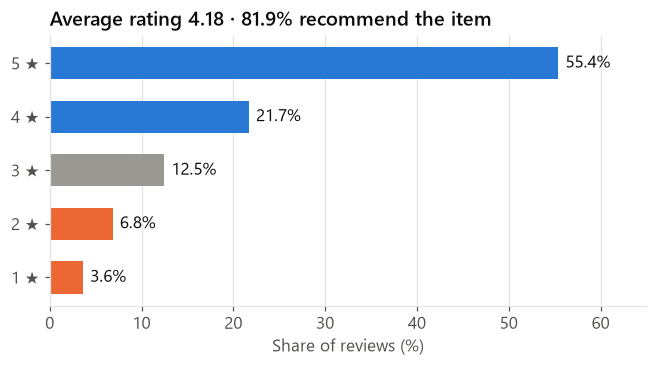

Rating
1     1.8
2     6.1
3    41.4
4    96.7
5    99.8
Name: Recommended IND, dtype: float64

In [5]:
share = df['Rating'].value_counts(normalize=True).sort_index(ascending=False) * 100
colors = [POS, POS, NEU, NEG, NEG]
fig, ax = plt.subplots(figsize=(7, 3.2))
bars = ax.barh([f'{r} ★' for r in share.index], share.values, color=colors, height=0.6)
ax.invert_yaxis(); ax.grid(axis='y', visible=False)
for b, v in zip(bars, share.values):
    ax.text(v + 0.8, b.get_y() + b.get_height() / 2, f'{v:.1f}%', va='center', color=INK)
ax.set_xlabel('Share of reviews (%)'); ax.set_xlim(0, 65)
ax.set_title(f"Average rating {KEY['avg_rating']} · {KEY['recommend_share']}% recommend the item")
save(fig, '01_rating_distribution')

rec_by_rating = df.groupby('Rating')['Recommended IND'].mean().mul(100).round(1)
KEY['rating_share'] = share.round(1).to_dict()
KEY['recommend_by_rating'] = rec_by_rating.to_dict()
rec_by_rating

## 2 · From text to numerical data
Lecture slides 33–39: the simplest quantitative features of text are **number of words, word length, vocabulary size** and a **readability index** (Flesch Reading Ease = 206.835 − 1.015·words/sentences − 84.6·syllables/words; higher = easier).

In [6]:
df['n_words'] = df['Text Clean'].str.split().str.len()
df['n_chars'] = df['Text Clean'].str.len()
df['avg_word_len'] = df['Text Clean'].apply(lambda t: np.mean([len(w) for w in re.findall(r"[A-Za-z']+", t)]))
df['flesch'] = df['Text Clean'].apply(textstat.flesch_reading_ease)

all_tokens = [w for t in df['Text Clean'].str.lower() for w in re.findall(r"[a-z']+", t)]
print(f"Total tokens: {len(all_tokens):,} · vocabulary (unique words): {len(set(all_tokens)):,}")
print(f"Max review length: {df['n_chars'].max()} characters (texts are cut at ~500 characters)")

text_stats = df.groupby('Rating')[['n_words', 'avg_word_len', 'flesch']].mean().round(1)
KEY.update(total_tokens=len(all_tokens), vocabulary=len(set(all_tokens)),
           avg_words=round(df['n_words'].mean(), 1), avg_word_len=round(df['avg_word_len'].mean(), 2),
           avg_flesch=round(df['flesch'].mean(), 1), words_by_rating=text_stats['n_words'].to_dict())
text_stats

Total tokens: 1,355,340 · vocabulary (unique words): 14,219
Max review length: 508 characters (texts are cut at ~500 characters)


,n_words,avg_word_len,flesch
Rating,,,
1,58.5,4.1,80.2
2,61.9,4.0,81.2
3,64.1,4.0,81.7
4,63.2,4.0,82.0
5,57.8,4.1,81.9


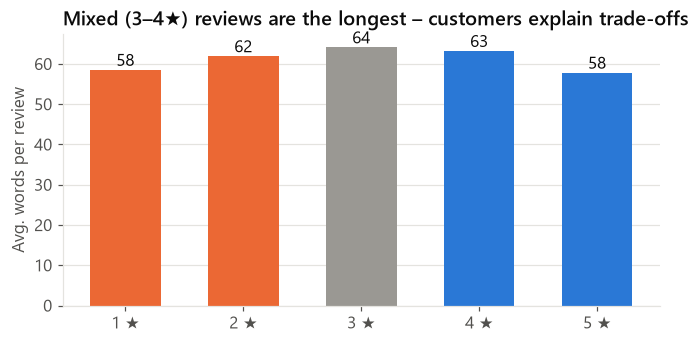

In [7]:
fig, ax = plt.subplots(figsize=(7, 3.2))
vals = text_stats['n_words']
ax.bar([f'{r} ★' for r in vals.index], vals.values, color=[NEG, NEG, NEU, POS, POS], width=0.6)
for i, v in enumerate(vals.values):
    ax.text(i, v + 1, f'{v:.0f}', ha='center', color=INK)
ax.set_ylabel('Avg. words per review'); ax.grid(axis='x', visible=False)
ax.set_title('Mixed (3–4★) reviews are the longest – customers explain trade-offs')
save(fig, '02_review_length')

**Reading:** readability is high (Flesch ≈ 82, "easy") across all ratings, average word length ~4 letters – typical informal consumer language. Length differs little; 3★ reviewers write the most because they weigh pros and cons.

## 3 · NLP preprocessing
Tokenization → lower-casing → stop-word removal → lemmatization (slide 23).

Two versions are kept:
* `clean` – strict: stop-words removed, lemmatized (for word frequencies, TF-IDF, topic models)
* `clean_ng` – for n-grams we **keep** negations and intensifiers (*not, too, very, no*), because "*not flattering*" or "*too big*" carry the meaning.

In [8]:
lemmatizer = WordNetLemmatizer()
STOP = set(stopwords.words('english'))
KEEP_FOR_NGRAMS = {'not', 'no', 'too', 'very', 'up', 'down', 'off', 'over', 'out', 'small', 'large', 'big'}
STOP_NG = STOP - KEEP_FOR_NGRAMS

def tokenize(text):
    text = text.lower().replace("can't", 'can not').replace("won't", 'will not').replace("n't", ' not')
    return re.findall(r"[a-z]+", text)

def preprocess(text):
    return [lemmatizer.lemmatize(w) for w in tokenize(text) if w not in STOP and len(w) > 2]

def preprocess_ngram(text):
    return ' '.join(w for w in tokenize(text) if w not in STOP_NG)

df['tokens'] = df['text'].apply(preprocess)
df['clean'] = df['tokens'].str.join(' ')
df['clean_ng'] = df['text'].apply(preprocess_ngram)

example = df.iloc[2]
print('ORIGINAL :', example['text'][:300])
print('TOKENS   :', example['tokens'][:30])
print('N-GRAM   :', example['clean_ng'][:200])

ORIGINAL : Some major design flaws. I had such high hopes for this dress and really wanted it to work for me. i initially ordered the petite small (my usual size) but i found this to be outrageously small. so small in fact that i could not zip it up! i reordered it in petite medium, which was just ok. overall,
TOKENS   : ['major', 'design', 'flaw', 'high', 'hope', 'dress', 'really', 'wanted', 'work', 'initially', 'ordered', 'petite', 'small', 'usual', 'size', 'found', 'outrageously', 'small', 'small', 'fact', 'could', 'zip', 'reordered', 'petite', 'medium', 'overall', 'top', 'half', 'comfortable', 'fit']
N-GRAM   : major design flaws high hopes dress really wanted work initially ordered petite small usual size found outrageously small small fact could not zip up reordered petite medium ok overall top half comfor


## 4 · Word and n-gram frequencies

In [9]:
def top_words(mask, n=20):
    return Counter(w for toks in df.loc[mask, 'tokens'] for w in set(toks)).most_common(n)

top_neg = pd.DataFrame(top_words(NEG_MASK), columns=['word', 'reviews'])
top_pos = pd.DataFrame(top_words(POS_MASK), columns=['word', 'reviews'])
top_neg['share %'] = (top_neg['reviews'] / NEG_MASK.sum() * 100).round(1)
top_pos['share %'] = (top_pos['reviews'] / POS_MASK.sum() * 100).round(1)
pd.concat({'negative (1-2★)': top_neg, 'positive (4-5★)': top_pos}, axis=1)

negative (1-2★)                 positive (4-5★)                
              word reviews share %            word reviews share %
0             like     862    36.4            love    7193    41.2
1             look     737    31.1             fit    6922    39.7
2              fit     702    29.6            size    5546    31.8
3            would     668    28.2           great    5487    31.4
4            dress     627    26.5           dress    5120    29.3
5              top     607    25.6           color    4941    28.3
6           fabric     601    25.4            wear    4727    27.1
7             size     559    23.6             top    4576    26.2
8             back     550    23.2            look    4183    24.0
9            color     483    20.4            like    4133    23.7
10         ordered     476    20.1         perfect    3611    20.7
11            love     447    18.9           would    3083    17.7
12           small     435    18.4      flattering    2990    17.1
13          really     422    17.8          fabric    2985    17.1
14            wear     404    17.0       beautiful    2978    17.1
15        material     392    16.5     comfortable    2971    17.0
16         quality     363    15.3            soft    2911    16.7
17             way     359    15.1          little    2902    16.6
18            much     354    14.9           small    2863    16.4
19             one     347    14.6            cute    2836    16.3

Raw frequencies are dominated by product words (*dress, top, fit, size*) in **both** groups – they tell us what customers talk about, not what makes them unhappy. Word clouds make this visible; sections 6 and 8 separate the signal.

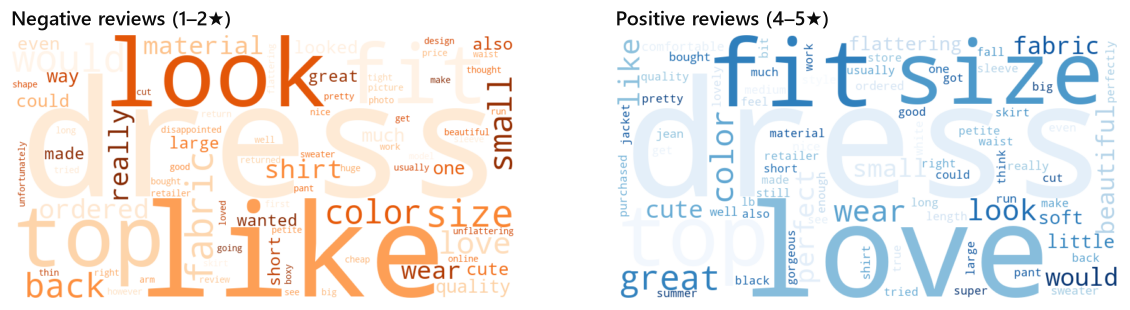

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for ax, mask, title, cmap in [(axes[0], NEG_MASK, 'Negative reviews (1–2★)', 'Oranges'),
                              (axes[1], POS_MASK, 'Positive reviews (4–5★)', 'Blues')]:
    freq = Counter(w for toks in df.loc[mask, 'tokens'] for w in toks)
    wc = WordCloud(width=800, height=420, background_color='white', colormap=cmap,
                   max_words=80, random_state=1).generate_from_frequencies(freq)
    ax.imshow(wc, interpolation='bilinear'); ax.axis('off'); ax.set_title(title)
save(fig, '03_wordclouds')

In [11]:
def top_ngrams(mask, n=15, ngram=(2, 3)):
    cv = CountVectorizer(ngram_range=ngram, min_df=20, binary=True)
    X = cv.fit_transform(df.loc[mask, 'clean_ng'])
    s = pd.Series(np.asarray(X.sum(0)).ravel(), cv.get_feature_names_out())
    return (s.sort_values(ascending=False).head(n) / mask.sum() * 100).round(1)

ngrams = pd.concat([top_ngrams(NEG_MASK).rename_axis('negative n-gram').reset_index(name='% of 1-2★'),
                    top_ngrams(POS_MASK).rename_axis('positive n-gram').reset_index(name='% of 4-5★')], axis=1)
ngrams

,negative n-gram,% of 1-2★,positive n-gram,% of 4-5★
0,wanted love,7.0,true size,6.9
1,going back,6.2,not too,4.9
2,not flattering,6.1,very flattering,4.9
3,way too,5.7,love dress,4.3
4,could not,5.7,size down,3.5
5,looked like,5.6,looks great,3.3
6,looks like,4.9,love top,3.3
7,would not,4.8,very comfortable,3.1
8,not work,4.8,usually wear,3.1
9,too much,4.5,up down,3.1


### Sizing language (n-gram counts)
Bigrams like *runs small / runs large* and *size up / size down* turn free text into a sizing signal.

In [12]:
size_patterns = {
    'runs small':  r'\b(runs?|running|ran|fits?) (a )?(bit |little |very |really )?small\b',
    'runs large':  r'\b(runs?|running|ran|fits?) (a )?(bit |little |very |really )?(large|big)\b',
    'size up':     r'\b(size|sized|go|went|order(ed)?) up\b',
    'size down':   r'\b(size|sized|go|went|order(ed)?) down\b',
    'too small / tight': r'\btoo (small|tight)\b',
    'too big / large':   r'\btoo (big|large|loose|boxy)\b',
    'true to size':      r'\btrue to size\b|\btts\b',
}
low_text = df['text'].str.lower()
size_tab = pd.DataFrame({name: low_text.str.contains(p) for name, p in size_patterns.items()})
size_share = size_tab.mean().mul(100).round(1)
any_mismatch = size_tab.drop(columns='true to size').any(axis=1)
KEY['sizing'] = size_share.to_dict()
KEY['size_mismatch_share'] = round(any_mismatch.mean() * 100, 1)
KEY['size_mismatch_share_pos'] = round(any_mismatch[POS_MASK].mean() * 100, 1)
print(f"Reviews with a size-mismatch phrase: {KEY['size_mismatch_share']}% (positive reviews: {KEY['size_mismatch_share_pos']}%)")
size_share

Reviews with a size-mismatch phrase: 20.3% (positive reviews: 19.3%)


runs small           3.1
runs large           5.7
size up              3.9
size down            4.7
too small / tight    2.9
too big / large      4.3
true to size         8.4
dtype: float64

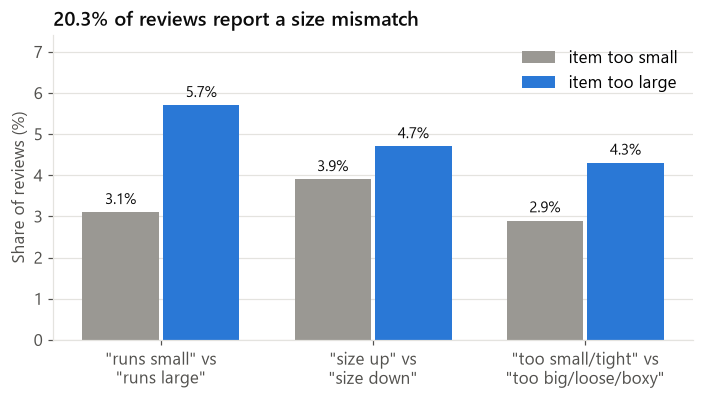

In [13]:
pairs = [('runs small', 'runs large'), ('size up', 'size down'), ('too small / tight', 'too big / large')]
labels = ['"runs small" vs\n"runs large"', '"size up" vs\n"size down"', '"too small/tight" vs\n"too big/loose/boxy"']
small = [size_share[a] for a, _ in pairs]; large = [size_share[b] for _, b in pairs]
x = np.arange(len(pairs)); w = 0.36
fig, ax = plt.subplots(figsize=(7.5, 3.6))
b1 = ax.bar(x - w/2 - 0.01, small, w, color=NEU, label='item too small')
b2 = ax.bar(x + w/2 + 0.01, large, w, color=POS, label='item too large')
for bars in (b1, b2):
    for b in bars:
        ax.text(b.get_x() + b.get_width()/2, b.get_height() + 0.2, f'{b.get_height():.1f}%', ha='center', color=INK, fontsize=10)
ax.set_xticks(x, labels); ax.set_ylabel('Share of reviews (%)'); ax.grid(axis='x', visible=False)
ax.legend(frameon=False, loc='upper right'); ax.set_ylim(0, max(large) * 1.3)
ax.set_title(f"{KEY['size_mismatch_share']}% of reviews report a size mismatch")
save(fig, '04_sizing_ngrams')

## 5 · Word co-occurrence
Which complaint words appear **together** in the same negative review? Counts of review pairs (document co-occurrence) for the most frequent content words in 1–2★ reviews.

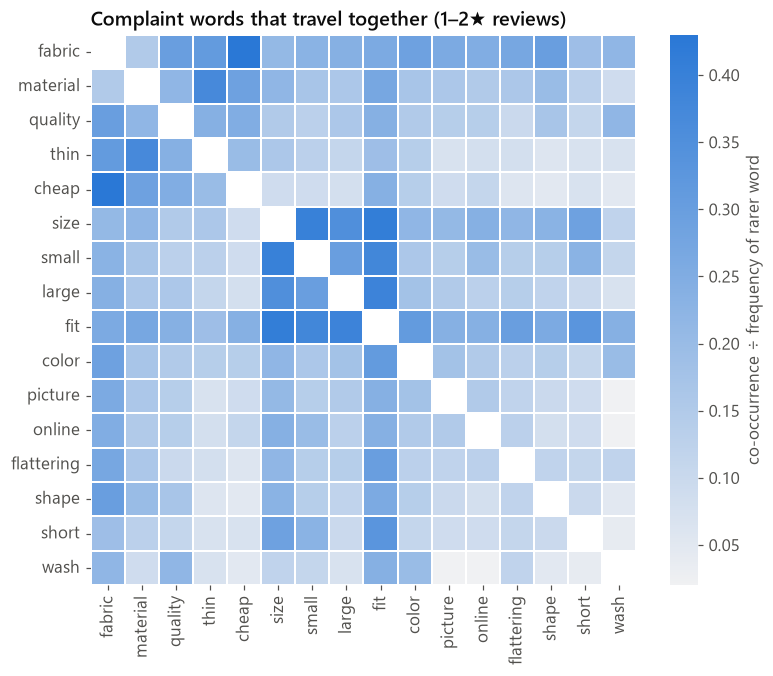

size      fit        214.0
          small      171.0
small     fit        164.0
fabric    fit        155.0
large     fit        110.0
fabric    size       108.0
          quality    107.0
fit       color      105.0
material  fit        103.0
fabric    color      101.0
dtype: float64

In [14]:
CO_TERMS = ['fabric', 'material', 'quality', 'thin', 'cheap', 'size', 'small', 'large',
            'fit', 'color', 'picture', 'online', 'flattering', 'shape', 'short', 'wash']
neg_sets = df.loc[NEG_MASK, 'text'].str.lower().apply(lambda t: set(re.findall(r'[a-z]+', t)))
co = pd.DataFrame(0, index=CO_TERMS, columns=CO_TERMS)
for s in neg_sets:
    present = [t for t in CO_TERMS if t in s]
    for a, b in combinations(present, 2):
        co.loc[a, b] += 1; co.loc[b, a] += 1
# normalise to Jaccard-like association: co-occurrence / min(freq)
freq = pd.Series({t: sum(t in s for s in neg_sets) for t in CO_TERMS})
assoc = co.div(np.minimum.outer(freq.values, freq.values)).round(2)
assoc = assoc.mask(np.eye(len(CO_TERMS), dtype=bool))

fig, ax = plt.subplots(figsize=(8, 6.5))
sns.heatmap(assoc, cmap=sns.light_palette(POS, as_cmap=True), linewidths=1, linecolor='white',
            cbar_kws={'label': 'co-occurrence ÷ frequency of rarer word'}, ax=ax)
ax.set_title('Complaint words that travel together (1–2★ reviews)')
ax.grid(False)
save(fig, '05_cooccurrence')

pairs_top = (co.where(np.triu(np.ones(co.shape), 1).astype(bool)).stack()
               .sort_values(ascending=False).head(10))
pairs_top

**Reading:** *thin–cheap–quality–material* form one cluster (fabric quality), *picture–online–color* another (product page vs. reality), *size–small–large–fit* a third. These clusters reappear in the topic model (section 8).

## 6 · Document-term matrix & TF-IDF – what separates bad from good reviews?
We build a document-term matrix (unigrams + bigrams) and compare

1. **TF-IDF**: average TF-IDF weight of each term in negative vs. positive reviews (slide 22), and
2. the **log-odds ratio**: how many times more likely a term appears in a negative than in a positive review.

In [15]:
tfidf = TfidfVectorizer(ngram_range=(1, 2), min_df=30, max_df=0.5, sublinear_tf=True)
X_tfidf = tfidf.fit_transform(df['clean_ng'])
terms = tfidf.get_feature_names_out()
print('Document-term matrix:', X_tfidf.shape)

mean_neg = np.asarray(X_tfidf[NEG_MASK.values].mean(0)).ravel()
mean_pos = np.asarray(X_tfidf[POS_MASK.values].mean(0)).ravel()
tfidf_diff = pd.Series(mean_neg - mean_pos, terms)
print('Highest TF-IDF weight in NEGATIVE vs positive:\n', tfidf_diff.sort_values(ascending=False).head(15).round(4).to_dict())
print('\nHighest TF-IDF weight in POSITIVE vs negative:\n', tfidf_diff.sort_values().head(15).round(4).to_dict())

Document-term matrix: (22641, 4201)
Highest TF-IDF weight in NEGATIVE vs positive:
 {'disappointed': 0.0195, 'looked': 0.0166, 'back': 0.0149, 'huge': 0.0147, 'wanted': 0.0137, 'like': 0.0136, 'unflattering': 0.0133, 'cheap': 0.0132, 'way': 0.0127, 'wanted love': 0.0119, 'returned': 0.0115, 'poor': 0.0113, 'too': 0.011, 'return': 0.0108, 'going back': 0.0107}

Highest TF-IDF weight in POSITIVE vs negative:
 {'love': -0.0214, 'great': -0.0203, 'perfect': -0.0178, 'comfortable': -0.0164, 'soft': -0.0128, 'little': -0.0119, 'fits': -0.0112, 'jeans': -0.0104, 'wear': -0.01, 'summer': -0.0087, 'beautiful': -0.0085, 'comfy': -0.0084, 'size': -0.0082, 'compliments': -0.0078, 'flattering': -0.0078}


In [16]:
cv_bin = CountVectorizer(ngram_range=(1, 2), min_df=30, binary=True)
X_bin = cv_bin.fit_transform(df['clean_ng'])
voc = cv_bin.get_feature_names_out()
c_neg = np.asarray(X_bin[NEG_MASK.values].sum(0)).ravel()
c_pos = np.asarray(X_bin[POS_MASK.values].sum(0)).ravel()
p_neg = (c_neg + 1) / (NEG_MASK.sum() + 2)
p_pos = (c_pos + 1) / (POS_MASK.sum() + 2)
lor = pd.DataFrame({'term': voc, 'neg_reviews': c_neg, 'pos_reviews': c_pos,
                    'neg %': (p_neg * 100).round(1), 'pos %': (p_pos * 100).round(1),
                    'ratio neg/pos': (p_neg / p_pos).round(1), 'ratio pos/neg': (p_pos / p_neg).round(1)})
neg_terms = lor[lor.neg_reviews >= 50].sort_values('ratio neg/pos', ascending=False)
pos_terms = lor[lor.pos_reviews >= 300].sort_values('ratio pos/neg', ascending=False)
neg_terms.head(25)

,term,neg_reviews,pos_reviews,neg %,pos %,ratio neg/pos,ratio pos/neg
3844,very disappointed,76,6,3.2,0.0,80.9,0.0
2661,poor quality,71,10,3.0,0.1,48.2,0.0
143,awful,63,11,2.7,0.1,39.2,0.0
2660,poor,130,24,5.5,0.1,38.5,0.0
3922,wanted like,50,9,2.2,0.1,37.5,0.0
775,disappointing,106,26,4.5,0.2,29.2,0.0
776,disappointment,54,16,2.3,0.1,23.8,0.0
3923,wanted love,165,53,7.0,0.3,22.6,0.0
3509,terrible,71,26,3.0,0.2,19.6,0.1
1336,going back,147,59,6.2,0.3,18.1,0.1


In [17]:
pos_terms.head(20)

,term,neg_reviews,pos_reviews,neg %,pos %,ratio neg/pos,ratio pos/neg
1495,highly recommend,1,365,0.1,2.1,0.0,24.9
887,dressed,3,562,0.2,3.2,0.1,19.1
1494,highly,2,411,0.1,2.4,0.1,18.7
889,dressed up,3,520,0.2,3.0,0.1,17.7
2014,many compliments,2,369,0.1,2.1,0.1,16.8
1167,fits perfectly,3,476,0.2,2.7,0.1,16.2
3827,versatile,6,742,0.3,4.3,0.1,14.4
7,absolutely love,2,303,0.1,1.7,0.1,13.8
574,compliments,9,975,0.4,5.6,0.1,13.3
1469,heels,3,302,0.2,1.7,0.1,10.3


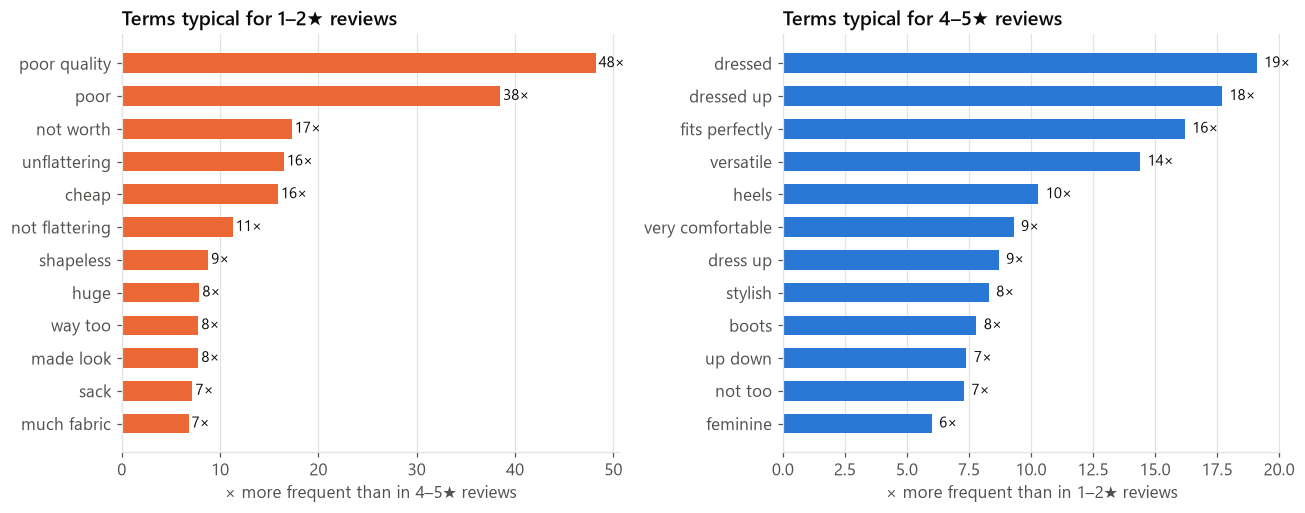

In [18]:
# Curated for the chart: drop pure emotion words to show the *product-related* drivers
EMOTION = {'disappointed', 'very disappointed', 'disappointing', 'disappointment', 'horrible', 'awful', 'terrible',
           'sad', 'sadly', 'unfortunately', 'wanted love', 'really wanted', 'wanted like', 'high hopes', 'hopes',
           'too bad', 'going back', 'returning', 'returned', 'idea', 'strange', 'weird', 'not sure', 'love love',
           'absolutely love', 'glad', 'fun', 'highly', 'highly recommend', 'wait wear', 'dress love', 'compliments',
           'many compliments', 'love dress', 'love top', 'not like', 'would not', 'looked like', 'look like', 'not look'}
neg_plot = neg_terms[~neg_terms.term.isin(EMOTION)].head(12)
pos_plot = pos_terms[~pos_terms.term.isin(EMOTION)].head(12)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.8), sharex=False)
ax = axes[0]
ax.barh(neg_plot.term, neg_plot['ratio neg/pos'], color=NEG, height=0.6); ax.invert_yaxis()
for i, v in enumerate(neg_plot['ratio neg/pos']): ax.text(v + 0.3, i, f'{v:.0f}×', va='center', color=INK, fontsize=10)
ax.set_title('Terms typical for 1–2★ reviews'); ax.set_xlabel('× more frequent than in 4–5★ reviews'); ax.grid(axis='y', visible=False)
ax = axes[1]
inv = pos_plot['ratio pos/neg']
ax.barh(pos_plot.term, inv, color=POS, height=0.6); ax.invert_yaxis()
for i, v in enumerate(inv): ax.text(v + 0.3, i, f'{v:.0f}×', va='center', color=INK, fontsize=10)
ax.set_title('Terms typical for 4–5★ reviews'); ax.set_xlabel('× more frequent than in 1–2★ reviews'); ax.grid(axis='y', visible=False)
fig.tight_layout()
save(fig, '06_distinctive_terms')

KEY['neg_terms'] = neg_plot.set_index('term')['ratio neg/pos'].to_dict()
KEY['pos_terms'] = pos_plot.set_index('term')['ratio pos/neg'].to_dict()
KEY['neg_terms_share'] = neg_plot.set_index('term')[['neg %', 'pos %']].to_dict('index')

## 7 · Sentiment analysis (VADER)
VADER is a lexicon- and rule-based sentiment model: every word has a polarity score; negations and intensifiers are handled by rules. The *compound* score runs from −1 (very negative) to +1 (very positive).

**Validation question:** does the text sentiment agree with the star rating?

In [19]:
sia = SentimentIntensityAnalyzer()
df['vader'] = df['text'].apply(lambda t: sia.polarity_scores(t)['compound'])
df['vader_label'] = pd.cut(df['vader'], [-1.01, -0.05, 0.05, 1.01], labels=['negative', 'neutral', 'positive'])

vader_by_rating = df.groupby('Rating')['vader'].mean().round(2)
corr = df[['vader', 'Rating']].corr(method='spearman').iloc[0, 1]
ct = pd.crosstab(df['sentiment_group'], df['vader_label'], normalize='index').mul(100).round(1)
KEY.update(vader_by_rating=vader_by_rating.to_dict(), vader_corr=round(corr, 2),
           vader_pos_in_neg=round(ct.loc['negative (1-2★)', 'positive'], 1))
print(f'Spearman correlation VADER vs. rating: {corr:.2f}')
ct

Spearman correlation VADER vs. rating: 0.45


vader_label,negative,neutral,positive
sentiment_group,,,
negative (1-2★),27.2,3.2,69.6
neutral (3★),12.9,2.3,84.9
positive (4-5★),1.3,0.3,98.4


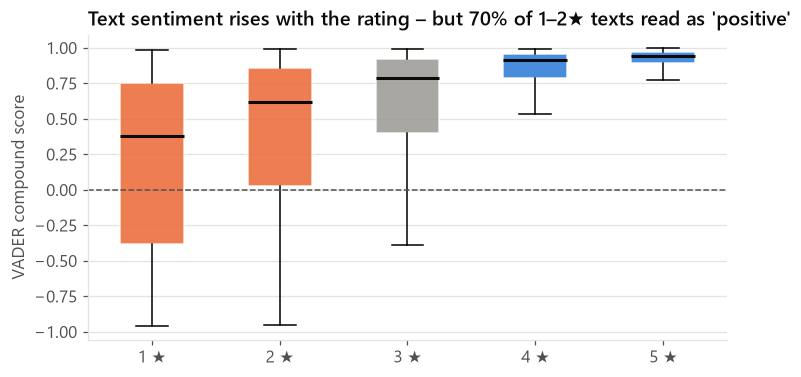

In [20]:
fig, ax = plt.subplots(figsize=(7.5, 3.6))
data = [df.loc[df.Rating == r, 'vader'] for r in range(1, 6)]
bp = ax.boxplot(data, widths=0.5, patch_artist=True, showfliers=False,
                medianprops=dict(color=INK, linewidth=2))
for patch, c in zip(bp['boxes'], [NEG, NEG, NEU, POS, POS]):
    patch.set_facecolor(c); patch.set_alpha(0.85); patch.set_edgecolor('white')
ax.set_xticks(range(1, 6), [f'{r} ★' for r in range(1, 6)])
ax.axhline(0, color=INK2, lw=1, ls='--')
ax.set_ylabel('VADER compound score'); ax.grid(axis='x', visible=False)
ax.set_title(f"Text sentiment rises with the rating – but {KEY['vader_pos_in_neg']:.0f}% of 1–2★ texts read as 'positive'")
save(fig, '07_vader_vs_rating')

In [21]:
# Why does VADER fail? Look at negative reviews that VADER scores as clearly positive
df.loc[NEG_MASK & (df.vader > 0.8), ['Rating', 'vader', 'text']].head(5)

,Rating,vader,text
5,2,0.9431,"Not for the very petite. I love tracy reese dresses, but this one is not for the very petite. i am just under 5 feet..."
68,2,0.9479,I wanted to love this top.... I really loved this top online and wanted to love it in person. it is soft and the pat...
71,2,0.9322,"Short and boxy. Why do designers keep making crop tops??!! i can't imagine this would be flattering on anyone, espec..."
85,1,0.8287,"I was really hoping to like this, but it did not look the way it does on the model, at least not on me. the sharkbit..."
97,1,0.9046,"Huge. I was very excited to order this top in red xs. so cute, but it was huge, shapeless and support thin! it had t..."


**Reading:** VADER captures the overall direction (correlation with rating ≈ 0.5), but half of all 1–2★ reviews are scored *positive*. Disappointed customers write "*I wanted to love this… beautiful color… but it fits like a tent*": the positive words outnumber the decisive negative one. Lesson for management reporting: **lexicon-based sentiment is not a reliable substitute for the star rating** – the value of the text lies in *why* (sections 6 and 8), not in a sentiment score.

## 8 · Topic modeling (LDA) – why are customers unhappy?
Latent Dirichlet Allocation (slides 47–49) assumes every review is a mixture of topics and every topic a distribution over words. We fit LDA on all **1–3★ reviews** (the dissatisfied and lukewarm customers) and let the algorithm find the complaint themes – no keyword lists defined in advance.

Product-type words (*dress, top, shirt…*) and generic verbs are removed so topics describe *issues*, not product categories.

In [22]:
DOMAIN_STOP = {'dress', 'top', 'shirt', 'wear', 'would', 'one', 'like', 'get', 'look', 'really', 'also', 'could',
               'retailer', 'item', 'bought', 'order', 'ordered', 'got', 'even', 'way', 'still', 'much', 'make',
               'love', 'cute', 'great', 'nice', 'beautiful', 'pretty', 'wanted', 'going', 'think', 'thought', 'tried'}
low = df[LOW_MASK].copy()
cv_lda = CountVectorizer(max_df=0.4, min_df=15, stop_words=list(STOP | DOMAIN_STOP))
X_lda = cv_lda.fit_transform(low['clean'])
lda_terms = cv_lda.get_feature_names_out()
print('LDA input:', X_lda.shape)

# choose k: compare perplexity for a few values (lower = better fit), then pick an interpretable k
for k in [5, 6, 7, 8, 9, 10]:
    m = LatentDirichletAllocation(n_components=k, random_state=42, learning_method='batch', max_iter=20).fit(X_lda)
    print(k, round(m.perplexity(X_lda), 1))

LDA input: (5193, 1111)


5 578.8


6 585.6


7 593.2


8 601.7


9 602.7


10 608.0


In [23]:
K = 8
lda = LatentDirichletAllocation(n_components=K, random_state=42, learning_method='batch', max_iter=40)
doc_topic = lda.fit_transform(X_lda)
for i, comp in enumerate(lda.components_):
    print(f'Topic {i}:', ' · '.join(lda_terms[comp.argsort()[::-1][:12]]))

Topic 0: size · small · large · fit · run · big · medium · usually · tight · arm · huge · petite
Topic 1: short · length · long · petite · shorter · longer · inch · model · hit · fit · high · suit
Topic 2: sweater · looked · back · color · online · boxy · disappointed · loved · washed · wash · dry · model
Topic 3: fit · fabric · flattering · waist · work · made · body · cut · looked · shape · hip · color
Topic 4: arm · back · button · hole · zipper · quality · sweater · first · sleeve · side · seam · design
Topic 5: fabric · quality · material · price · thin · design · good · feel · worth · felt · fit · cheap
Topic 6: pant · color · jean · fit · pair · white · black · blue · leg · stretch · size · comfortable
Topic 7: skirt · color · see · material · fabric · picture · sheer · photo · back · thin · white · online


We read the top words and a few example reviews per topic, then give each topic a business name:

In [24]:
TOPIC_NAMES = {0: "Sizing: runs small / large", 1: "Length & proportions", 2: "Sweaters: boxy, shrinks in the wash", 3: "Unflattering cut & shape", 4: "Workmanship: buttons, zips, seams", 5: "Cheap fabric for the price", 6: "Pants & jeans fit", 7: "See-through / differs from photo"}
low['topic'] = doc_topic.argmax(1)
low['topic_name'] = low['topic'].map(TOPIC_NAMES)
low['topic_weight'] = doc_topic.max(1)

for i in range(K):
    ex = low[low.topic == i].sort_values('topic_weight', ascending=False)['text'].head(2).tolist()
    print(f'\n### {i} · {TOPIC_NAMES[i]}')
    for e in ex: print('  –', e[:220])


### 0 · Sizing: runs small / large
  – Cups size too big!. Loved the design and quality of this suit but the cups seemed huge. i weight 135lbs 5'6" and wear a 34c. i bought a large in this suit because other reviews said it ran small (normally i wear a size m
  – Stylish top, but neck opening too small!. I was so excited to get this top! i love the bow at the neck and the frill sleeves, so current. unfortunately, it was difficult for me to pull it over my head! the neck opening i

### 1 · Length & proportions
  – Not so sure about it. I was really excited for this dress to come and hoped it would work well for a couple of holiday parties that i will be going to this season. i wasn't sure what i thought when trying it on, but i am
  – Yup, no ruffle.. Sooo this adorable blouse is indeed different than pictured. no ruffle, such a bummer, sleeves are much longer, and yes it's teared in the front and back. also the button opening on the back is much long

### 2 · Sweaters: boxy, shrinks i

In [25]:
topic_summary = (low.groupby('topic_name')
                   .agg(reviews=('text', 'size'), avg_rating=('Rating', 'mean'),
                        recommend=('Recommended IND', 'mean'))
                   .assign(share=lambda d: d.reviews / d.reviews.sum() * 100)
                   .sort_values('share', ascending=False))
topic_summary['avg_rating'] = topic_summary['avg_rating'].round(2)
topic_summary['recommend'] = (topic_summary['recommend'] * 100).round(1)
topic_summary['share'] = topic_summary['share'].round(1)
topic_summary['top words'] = [ ', '.join(lda_terms[lda.components_[[k for k, v in TOPIC_NAMES.items() if v == n][0]].argsort()[::-1][:6]])
                               for n in topic_summary.index]
KEY['topics'] = topic_summary.reset_index().to_dict('records')
topic_summary

,reviews,avg_rating,recommend,share,top words
topic_name,,,,,
Unflattering cut & shape,1241,2.46,21.5,23.9,"fit, fabric, flattering, waist, work, made"
Sizing: runs small / large,1055,2.50,36.6,20.3,"size, small, large, fit, run, big"
See-through / differs from photo,655,2.30,19.2,12.6,"skirt, color, see, material, fabric, picture"
Cheap fabric for the price,585,2.38,24.1,11.3,"fabric, quality, material, price, thin, design"
"Workmanship: buttons, zips, seams",555,2.27,18.4,10.7,"arm, back, button, hole, zipper, quality"
"Sweaters: boxy, shrinks in the wash",452,2.10,11.3,8.7,"sweater, looked, back, color, online, boxy"
Pants & jeans fit,359,2.35,27.9,6.9,"pant, color, jean, fit, pair, white"
Length & proportions,291,2.58,36.4,5.6,"short, length, long, petite, shorter, longer"


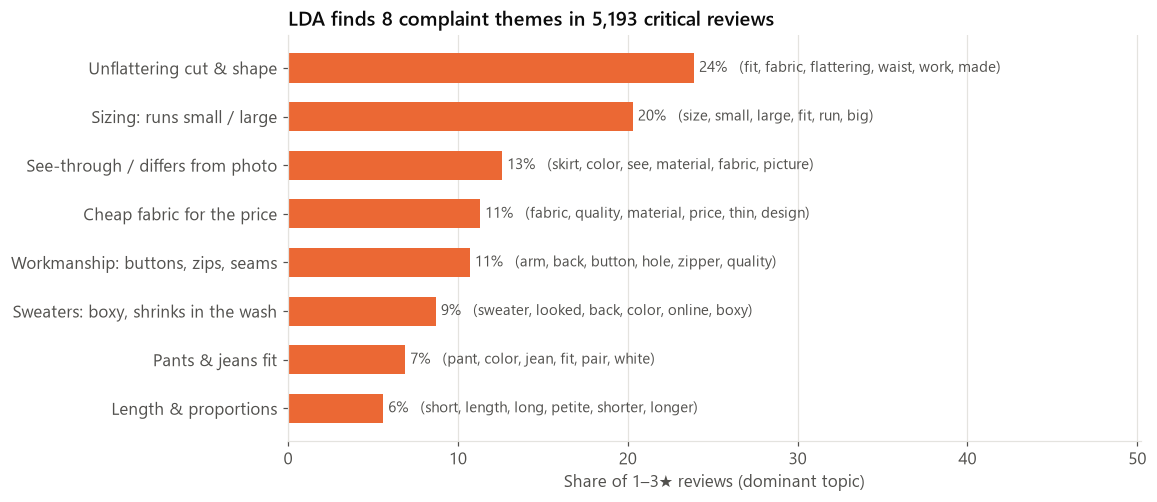

In [26]:
ts = topic_summary.iloc[::-1]
fig, ax = plt.subplots(figsize=(10, 4.8))
bars = ax.barh(ts.index, ts['share'], color=NEG, height=0.6)
for b, (_, row) in zip(bars, ts.iterrows()):
    ax.text(b.get_width() + 0.3, b.get_y() + b.get_height()/2,
            f"{row['share']:.0f}%   ({row['top words']})", va='center', color=INK2, fontsize=9.5)
ax.set_xlim(0, ts['share'].max() * 2.1); ax.grid(axis='y', visible=False)
ax.set_xlabel('Share of 1–3★ reviews (dominant topic)')
ax.set_title(f'LDA finds {K} complaint themes in {len(low):,} critical reviews')
save(fig, '08_lda_topics')

## 9 · Topics by department and age group

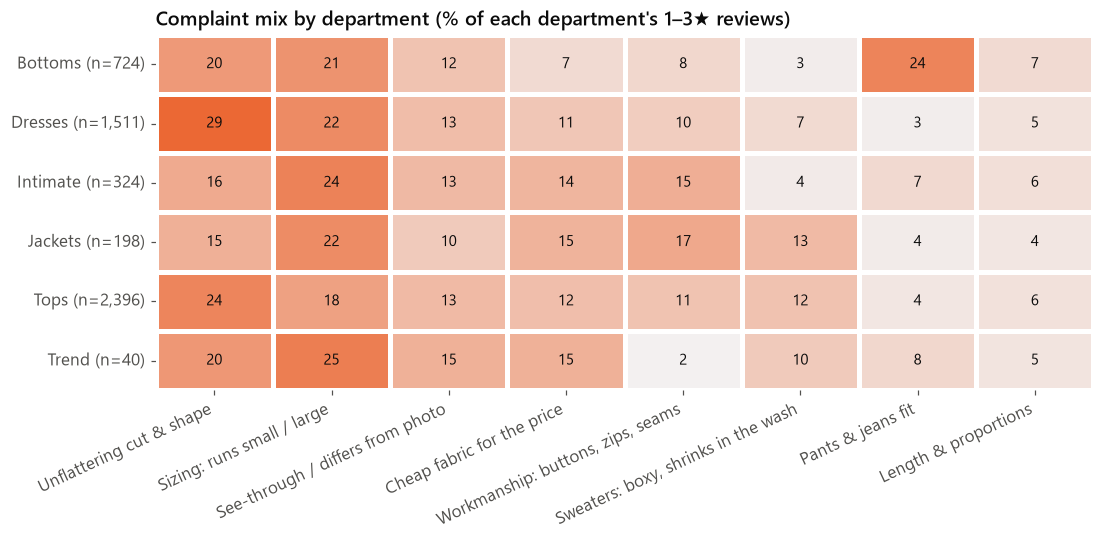

topic_name,Unflattering cut & shape,Sizing: runs small / large,See-through / differs from photo,Cheap fabric for the price,"Workmanship: buttons, zips, seams","Sweaters: boxy, shrinks in the wash",Pants & jeans fit,Length & proportions
Bottoms (n=724),19.6,20.9,11.5,6.8,7.5,3.3,23.8,6.8
"Dresses (n=1,511)",29.3,22.4,12.6,10.7,9.5,7.0,3.1,5.4
Intimate (n=324),16.4,24.1,13.3,14.2,15.4,3.7,7.1,5.9
Jackets (n=198),15.2,22.2,10.1,14.6,16.7,13.1,3.5,4.5
"Tops (n=2,396)",23.6,18.1,13.1,12.3,11.4,11.7,4.5,5.5
Trend (n=40),20.0,25.0,15.0,15.0,2.5,10.0,7.5,5.0


In [27]:
dept_topic = (pd.crosstab(low['Department Name'], low['topic_name'], normalize='index') * 100).round(1)
dept_topic = dept_topic[topic_summary.index]
dept_n = low['Department Name'].value_counts()
dept_topic.index = [f'{d} (n={dept_n[d]:,})' for d in dept_topic.index]

fig, ax = plt.subplots(figsize=(11, 4.2))
sns.heatmap(dept_topic, annot=True, fmt='.0f', cmap=sns.light_palette(NEG, as_cmap=True), linewidths=2,
            linecolor='white', cbar=False, ax=ax, annot_kws={'color': INK, 'fontsize': 10})
ax.set_xlabel(''); ax.set_ylabel(''); ax.grid(False)
ax.set_xticklabels(ax.get_xticklabels(), rotation=25, ha='right')
ax.set_title('Complaint mix by department (% of each department\'s 1–3★ reviews)')
save(fig, '09_topics_by_department')
KEY['dept_topic'] = dept_topic.to_dict('index')
dept_topic

In [28]:
dept = (df.groupby('Department Name')
          .agg(reviews=('Rating', 'size'), avg_rating=('Rating', 'mean'),
               negative=('Rating', lambda r: (r <= 2).mean() * 100),
               recommend=('Recommended IND', lambda r: r.mean() * 100))
          .round(2).sort_values('reviews', ascending=False))
KEY['departments'] = dept.reset_index().to_dict('records')
dept

,reviews,avg_rating,negative,recommend
Department Name,,,,
Tops,10048,4.16,10.91,81.07
Dresses,6145,4.14,11.08,80.52
Bottoms,3662,4.28,8.66,84.95
Intimate,1653,4.27,8.89,84.63
Jackets,1002,4.25,10.78,83.33
Trend,118,3.84,17.80,74.58


In [29]:
age = (df.groupby('age_group', observed=True)
         .agg(reviews=('Rating', 'size'), avg_rating=('Rating', 'mean'),
              negative=('Rating', lambda r: (r <= 2).mean() * 100),
              recommend=('Recommended IND', lambda r: r.mean() * 100),
              vader=('vader', 'mean'))
         .round(2))
age['share'] = (age['reviews'] / age['reviews'].sum() * 100).round(1)
age_topic = (pd.crosstab(low['age_group'], low['topic_name'], normalize='index') * 100).round(1)[topic_summary.index]
KEY['age'] = age.reset_index().astype({'age_group': str}).to_dict('records')
KEY['age_topic'] = {str(k): v for k, v in age_topic.to_dict('index').items()}
display(age)
age_topic

,reviews,avg_rating,negative,recommend,vader,share
age_group,,,,,,
18-29,2839,4.19,9.58,81.37,0.79,12.5
30-39,7346,4.15,10.88,80.86,0.78,32.4
40-49,5903,4.14,11.33,80.82,0.77,26.1
50-59,3834,4.23,9.83,83.57,0.78,16.9
60+,2719,4.29,9.30,85.14,0.79,12.0


topic_name,Unflattering cut & shape,Sizing: runs small / large,See-through / differs from photo,Cheap fabric for the price,"Workmanship: buttons, zips, seams","Sweaters: boxy, shrinks in the wash",Pants & jeans fit,Length & proportions
age_group,,,,,,,,
18-29,25.9,19.5,13.5,12.6,12.0,7.1,5.0,4.4
30-39,24.7,20.6,12.1,11.0,10.6,8.5,6.1,6.5
40-49,23.3,19.7,12.2,10.9,11.1,9.4,7.6,5.8
50-59,23.6,20.9,12.8,10.9,9.7,8.5,8.6,5.2
60+,20.9,21.1,14.2,12.1,10.0,9.6,7.7,4.3


## 10 · Key findings for management

In [30]:
with open('results/key_numbers.json', 'w', encoding='utf-8') as f:
    json.dump(KEY, f, indent=2, ensure_ascii=False, default=float)

print(f"1. Satisfaction is high: avg {KEY['avg_rating']}★, {KEY['recommend_share']}% recommend; "
      f"{KEY['n_negative']:,} negative (1–2★) of {KEY['n_docs']:,} reviews with text.")
print(f"2. Sizing is the most frequent issue: {KEY['size_mismatch_share']}% of reviews report a size mismatch, "
      f"even {KEY['size_mismatch_share_pos']}% of positive ones.")
t = topic_summary
print(f"3. LDA themes in 1–3★ reviews: " + '; '.join(f'{n} {s:.0f}%' for n, s in t['share'].items()))
print(f"4. Distinctive negative terms: " + ', '.join(list(KEY['neg_terms'])[:8]))
print(f"5. VADER sentiment correlates with ratings (ρ={KEY['vader_corr']}) but scores "
      f"{KEY['vader_pos_in_neg']:.0f}% of 1–2★ reviews as positive – text explains *why*, not *how much*.")

1. Satisfaction is high: avg 4.18★, 81.9% recommend; 2,370 negative (1–2★) of 22,641 reviews with text.
2. Sizing is the most frequent issue: 20.3% of reviews report a size mismatch, even 19.3% of positive ones.
3. LDA themes in 1–3★ reviews: Unflattering cut & shape 24%; Sizing: runs small / large 20%; See-through / differs from photo 13%; Cheap fabric for the price 11%; Workmanship: buttons, zips, seams 11%; Sweaters: boxy, shrinks in the wash 9%; Pants & jeans fit 7%; Length & proportions 6%
4. Distinctive negative terms: poor quality, poor, not worth, unflattering, cheap, not flattering, shapeless, huge
5. VADER sentiment correlates with ratings (ρ=0.45) but scores 70% of 1–2★ reviews as positive – text explains *why*, not *how much*.


### Limitations
* No review dates in the export → no trends over time.
* Review texts are truncated at ~500 characters.
* LDA assigns one dominant topic per review for reporting; real reviews mix topics. Topic names are our interpretation of the top words.
* VADER is a general-purpose lexicon, not tuned to fashion vocabulary ("*runs small*", "*tent*").
* Trend department (119 reviews) is too small for firm conclusions.